# Лабораторная работа 1. Диагностика обучения MLP

Ноутбук к заданию `lab1.docx`. Сначала готовлю выборки, потом обучаю MLP
в конфигурациях A-F и собираю метрики.

## 1. Данные и разбиение

Беру `make_moons`: 2400 объектов, шум 0.25, `random_state=2026`.
Сначала отделяю 20% в test, из остатка 25% уходит в validation.
Оба вызова `train_test_split` идут с `random_state=2026` и `stratify`,
поэтому доли классов во всех выборках одинаковые.

In [1]:
from pathlib import Path
import json

import numpy as np
import torch
import sklearn
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# один поток на CPU, как требует задание
torch.set_num_threads(1)

RANDOM_STATE = 2026
ROOT = Path.cwd()
FIG_DIR = ROOT / "figures"
RES_DIR = ROOT / "results"
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

np.set_printoptions(precision=4, suppress=True)
print("torch:", torch.__version__)
print("numpy:", np.__version__)
print("sklearn:", sklearn.__version__)
print("устройство: cpu")

torch: 2.15.0+cpu
numpy: 2.5.4
sklearn: 1.9.1
устройство: cpu


In [2]:
X, y = make_moons(n_samples=2400, noise=0.25, random_state=RANDOM_STATE)
print("X:", X.shape, "y:", y.shape)

X_train_all, X_test, y_train_all, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_all, test_size=0.25, random_state=RANDOM_STATE,
    stratify=y_train_all,
)
print("train / val / test:", len(X_train), len(X_val), len(X_test))

X: (2400, 2) y: (2400,)
train / val / test: 1440 480 480


In [3]:
# копия до масштабирования нужна для графика
X_train_raw = X_train.copy()

scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

In [4]:
sizes = {"train": len(X_train), "val": len(X_val), "test": len(X_test)}
assert sizes == {"train": 1440, "val": 480, "test": 480}, sizes

class_counts = {}
for name, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    counts = np.bincount(yy, minlength=2)
    class_counts[name] = counts.tolist()
    assert counts.min() > 0, name
    print(f"{name}: 0 -> {counts[0]}, 1 -> {counts[1]}")

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
print("средние train:", mean)
print("std train:", std)
assert np.allclose(mean, 0.0, atol=1e-5)
assert np.allclose(std, 1.0, atol=1e-5)

train: 0 -> 720, 1 -> 720
val: 0 -> 240, 1 -> 240
test: 0 -> 240, 1 -> 240
средние train: [-0.  0.]
std train: [1. 1.]


In [5]:
summary = {
    "sizes": sizes,
    "class_counts": class_counts,
    "train_mean": [float(v) for v in mean],
    "train_std": [float(v) for v in std],
    "scaler_mean": [float(v) for v in scaler.mean_],
    "scaler_scale": [float(v) for v in scaler.scale_],
}
path = RES_DIR / "data_summary.json"
path.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print("сохранено:", path.relative_to(ROOT))

сохранено: results/data_summary.json


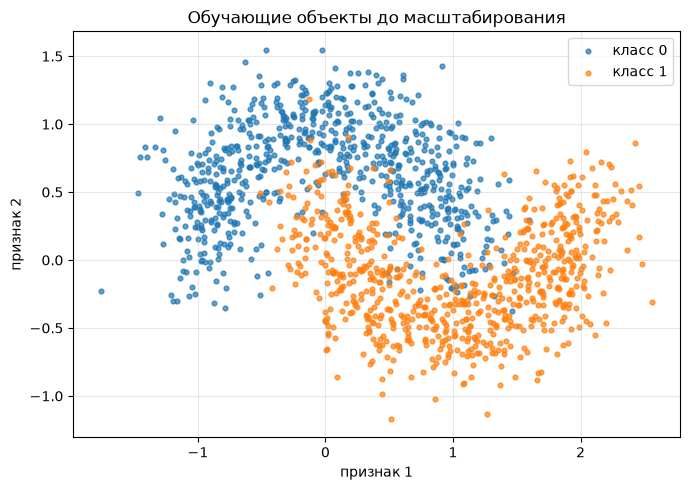

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_train_raw[y_train == 0, 0], X_train_raw[y_train == 0, 1],
           s=12, alpha=0.7, label="класс 0")
ax.scatter(X_train_raw[y_train == 1, 0], X_train_raw[y_train == 1, 1],
           s=12, alpha=0.7, label="класс 1")
ax.set_xlabel("признак 1")
ax.set_ylabel("признак 2")
ax.set_title("Обучающие объекты до масштабирования")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "scatter_train_raw.png", dpi=150)
plt.show()

## Что получилось

Размеры сошлись: 1440 / 480 / 480. В каждой выборке есть оба класса.
После `StandardScaler` средние по train близки к нулю, стандартные
отклонения к единице. Скалер обучен только на train. Если считать
средние и std по всем данным, в обучение попадает информация из
validation и test, а это утечка.

## 2. MLP и цикл обучения

Собираю MLP вручную: L скрытых слоев ширины 32, одна активация на запуск,
линейный выход на 2 логита. Скрытые слои инициализирую Xavier normal
или He normal, выход всегда Xavier, смещения нулевые.

Метрики считаю на полных train и val в режиме eval. Шаг обучения:
zero_grad, forward, loss, backward, step. Для каждого запуска задаю
`torch.manual_seed(seed)` до создания модели и отдельный генератор
для DataLoader с seed `10000 + seed`.

In [7]:
from torch.utils.data import DataLoader, TensorDataset
import torch.nn as nn
import torch.nn.functional as F

X_train_t = torch.from_numpy(X_train)
y_train_t = torch.from_numpy(y_train).long()
X_val_t = torch.from_numpy(X_val)
y_val_t = torch.from_numpy(y_val).long()
X_test_t = torch.from_numpy(X_test)
y_test_t = torch.from_numpy(y_test).long()

print(X_train_t.dtype, y_train_t.dtype)

torch.float32 torch.int64


In [8]:
ACTIVATIONS = {"sigmoid": torch.sigmoid, "tanh": torch.tanh, "relu": F.relu}
WIDTH = 32


class MLP(nn.Module):
    def __init__(self, n_hidden, width, activation, init):
        super().__init__()
        self.activation = ACTIVATIONS[activation]
        sizes = [2] + [width] * n_hidden + [2]
        self.layers = nn.ModuleList()
        for i in range(len(sizes) - 1):
            layer = nn.Linear(sizes[i], sizes[i + 1])
            if i < n_hidden:
                if init == "xavier":
                    nn.init.xavier_normal_(layer.weight, gain=1.0)
                elif init == "he":
                    nn.init.kaiming_normal_(layer.weight, mode="fan_in",
                                            nonlinearity="relu")
                else:
                    raise ValueError(init)
            else:
                nn.init.xavier_normal_(layer.weight, gain=1.0)
            nn.init.zeros_(layer.bias)
            self.layers.append(layer)

    def forward(self, x):
        h = x
        for layer in self.layers[:-1]:
            h = self.activation(layer(h))
        return self.layers[-1](h)


criterion = nn.CrossEntropyLoss(reduction="mean")

In [9]:
def compute_metrics(model, X, y):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        loss = criterion(logits, y).item()
        acc = (logits.argmax(dim=1) == y).float().mean().item()
    return loss, acc


def train_model(config, seed, epochs=100, batch_size=128):
    torch.manual_seed(seed)
    model = MLP(config["hidden"], WIDTH, config["activation"], config["init"])

    generator = torch.Generator().manual_seed(10000 + seed)
    loader = DataLoader(
        TensorDataset(X_train_t, y_train_t),
        batch_size=batch_size,
        shuffle=True,
        generator=generator,
    )

    if config["optimizer"] == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"])
    elif config["optimizer"] == "sgd":
        optimizer = torch.optim.SGD(model.parameters(), lr=config["lr"],
                                    momentum=0.0)
    else:
        raise ValueError(config["optimizer"])

    history = []
    tr_loss, tr_acc = compute_metrics(model, X_train_t, y_train_t)
    va_loss, va_acc = compute_metrics(model, X_val_t, y_val_t)
    history.append({"epoch": 0, "train_loss": tr_loss,
                    "train_accuracy": tr_acc, "val_loss": va_loss,
                    "val_accuracy": va_acc})

    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            if not torch.isfinite(loss):
                raise RuntimeError(f"loss не конечен на эпохе {epoch}")
            loss.backward()
            optimizer.step()

        tr_loss, tr_acc = compute_metrics(model, X_train_t, y_train_t)
        va_loss, va_acc = compute_metrics(model, X_val_t, y_val_t)
        history.append({"epoch": epoch, "train_loss": tr_loss,
                        "train_accuracy": tr_acc, "val_loss": va_loss,
                        "val_accuracy": va_acc})

    return model, history


CONFIGS = {
    "A": {"hidden": 6, "activation": "sigmoid", "init": "xavier",
          "optimizer": "adam", "lr": 0.003},
    "B": {"hidden": 6, "activation": "tanh", "init": "xavier",
          "optimizer": "adam", "lr": 0.003},
    "C": {"hidden": 6, "activation": "relu", "init": "xavier",
          "optimizer": "adam", "lr": 0.003},
    "D": {"hidden": 6, "activation": "relu", "init": "he",
          "optimizer": "adam", "lr": 0.003},
    "E": {"hidden": 6, "activation": "relu", "init": "he",
          "optimizer": "sgd", "lr": 0.05},
    "F": {"hidden": 1, "activation": "relu", "init": "he",
          "optimizer": "adam", "lr": 0.003},
}

### Самопроверка

Число параметров считаю вручную. Для L = 1: `2*32+32 + 32*2+2 = 162`.
Для L = 6: `2*32+32 + 5*(32*32+32) + 32*2+2 = 5442`.
Дальше сверяю с `sum(p.numel() for p in model.parameters())`.

In [10]:
xb = X_train_t[:8]
yb = y_train_t[:8]
torch.manual_seed(0)

for n_hidden, expected in ((1, 162), (6, 5442)):
    model = MLP(n_hidden, WIDTH, "relu", "he")
    logits = model(xb)
    loss = criterion(logits, yb)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"L={n_hidden}: вход {tuple(xb.shape)}, выход {tuple(logits.shape)}, "
          f"loss {loss.item():.4f}, loss.ndim={loss.ndim}, "
          f"параметров {n_params}")
    assert tuple(logits.shape) == (8, 2)
    assert loss.ndim == 0
    assert n_params == expected, (n_params, expected)

L=1: вход (8, 2), выход (8, 2), loss 0.7912, loss.ndim=0, параметров 162
L=6: вход (8, 2), выход (8, 2), loss 1.6682, loss.ndim=0, параметров 5442


In [11]:
torch.manual_seed(0)
model = MLP(6, WIDTH, "relu", "he")
model.zero_grad()
loss = criterion(model(xb), yb)
loss.backward()

for i, layer in enumerate(model.layers[:-1], start=1):
    grad = layer.weight.grad
    assert grad is not None, f"нет градиента у слоя {i}"
    assert grad.shape == layer.weight.shape, f"форма не совпала у слоя {i}"
    assert torch.isfinite(grad).all(), f"градиент не конечен у слоя {i}"
    print(f"слой {i}: grad {tuple(grad.shape)}, "
          f"норма {grad.norm().item():.4f}")

слой 1: grad (32, 2), норма 0.1766
слой 2: grad (32, 32), норма 0.5406
слой 3: grad (32, 32), норма 0.4276
слой 4: grad (32, 32), норма 0.4330
слой 5: grad (32, 32), норма 0.4464
слой 6: grad (32, 32), норма 0.3465


Проверки сошлись: вход (8, 2), выход (8, 2), loss скаляр. Параметров
162 при L = 1 и 5442 при L = 6. Градиенты всех скрытых слоев есть,
формы совпадают с весами, значения конечные.

### Короткий прогон цикла

Одна эпоха на конфигурации D, чтобы проверить, что обучение идет
и метрики считаются. Полные 100 эпох для A-F будут в разделе 3.

In [12]:
demo_model, demo_history = train_model(CONFIGS["D"], seed=11, epochs=1)
for row in demo_history:
    print(f"эпоха {row['epoch']}: train loss {row['train_loss']:.4f}, "
          f"train acc {row['train_accuracy']:.3f}, "
          f"val loss {row['val_loss']:.4f}, "
          f"val acc {row['val_accuracy']:.3f}")

эпоха 0: train loss 0.5591, train acc 0.778, val loss 0.5655, val acc 0.760
эпоха 1: train loss 0.2936, train acc 0.867, val loss 0.2988, val acc 0.856
